# №8 зертханалық жұмыс
## Деректерді k-means, DBSCAN және иерархиялық кластерлеу арқылы кластерлеу. PCA әдісімен өлшемділікті азайту.

Жұмыста екі қойылым бар. Сипаттамалық кластерлеу барлық 150 бақылауды қамтиды. PCA реконструкциясы 120 жолда оқытылғаннан кейін кейінге қалдырылған 30 жолда тексеріледі. Түрлер екі рәсім де оқытылғаннан кейін қолжетімді болады. Олар ARI мен кейінге қалдырылған проекция түстері үшін пайдаланылады.

Р. А. Фишердің Iris деректері CC BY 4.0 лицензиясымен таратылады. scikit-learn-нің түзетілген кіріктірілген нұсқасын пайдаланамыз. Бастапқы өлшемдер кестесі мен атрибуция файлы сақталады. Таза іске қосу `lab08_artifacts` каталогын жасайды. [UCI Iris, DOI 10.24432/C56C76](https://archive.ics.uci.edu/dataset/53/iris), [load_iris](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html).

### 1-қадам. Орта және өлшем бірліктері

Нұсқаларды жазыңыз. Бастапқы өлшемдер сантиметрмен берілген. Силуэт пен реконструкция MSE қатесі стандартталған кеңістікте есептеледі, әр көрсеткіштің өз популяциясы көрсетілген.

In [1]:
from pathlib import Path
import json

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import AgglomerativeClustering, DBSCAN, KMeans
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd() / "lab08_artifacts"
FIGURES = ROOT / "figures"
DATASETS = ROOT / "datasets"
FIGURES.mkdir(parents=True, exist_ok=True)
DATASETS.mkdir(parents=True, exist_ok=True)
plt.rcParams["font.family"] = "DejaVu Sans"
ATTRIBUTION = """Iris. Fisher, R. (1936). UCI Machine Learning Repository.
DOI: https://doi.org/10.24432/C56C76
Дереккөз: https://archive.ics.uci.edu/dataset/53/iris
Лицензия: CC BY 4.0 https://creativecommons.org/licenses/by/4.0/
Экспортталған өлшемдер sklearn.datasets.load_iris көшірмесінен алынған.
scikit-learn 0.20 нұсқасынан бастап екі бақылау Фишер мақаласы бойынша түзетілген.
Бұл — түзетілген sklearn нұсқасы. Түр белгілері 0, 1, 2 ретінде кодталған.
Экспорт row_id, target, species және pca_split қызметтік бағандарын қосады.
Жасанды бақылаулар қосылмаған. Метадеректер 2026-11-05 күні тексерілген.
"""



from IPython.display import display, Image
from importlib.metadata import version
for package in ("numpy", "pandas", "scikit-learn", "matplotlib"):
    print(package, version(package))


numpy 2.5.4
pandas 3.0.1
scikit-learn 1.9.1
matplotlib 3.11.2


### 2-қадам. Төрт өлшем және алдын ала берілген екі жоспар

Кластерлеу төрт белгінің бәрін пайдаланып, күлте жапырақшасының ұзындығы мен енін көрсетеді. PCA үшін екі компонентті, толық SVD, кездейсоқ split 80/20 және seed=2026 бекітеміз. Алдымен тек белгілер қолжетімді.

In [2]:
iris = load_iris(as_frame=True)
X = iris.data
print("Белгілер пішіні", X.shape)
print("Өлшемдер", list(X.columns))


Белгілер пішіні (150, 4)
Өлшемдер ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


### 3-қадам. Бір кеңістіктің төрт бөлінуі

StandardScaler сипаттамалық тәжірибенің 150 жолында үйретіледі. KMeans 3 кластер, n_init=20 және seed=2026 алады. GMM 3 компонент, full, n_init=10, reg_covar=1e-6, max_iter=500 және seed=2026 алады. Ward евклидтік қашықтықтар мен 3 топты пайдаланады. DBSCAN eps=.6 және min_samples=5 пайдаланады. Әр fit аргументі — тек белгілер матрицасы.

In [3]:
def fit_clusters(X):
    scaler = StandardScaler()
    Z = scaler.fit_transform(X)
    models = {
        "KMeans": KMeans(n_clusters=3, n_init=20, random_state=2026),
        "GMM": GaussianMixture(n_components=3, covariance_type="full", n_init=10,
                               reg_covar=1e-6, max_iter=500, random_state=2026),
        "Ward": AgglomerativeClustering(n_clusters=3, linkage="ward", metric="euclidean"),
        "DBSCAN": DBSCAN(eps=.6, min_samples=5),
    }
    labels = {name: model.fit_predict(Z) for name, model in models.items()}
    return {"Z": Z, "labels": labels, "scaler": scaler, "models": models}



cluster_state = fit_clusters(X)


### 5–6-қадамдар. PCA бөлуі және реконструкцияны есептеу

Индекстер стратификациясыз кездейсоқ бөлінеді. Жаңа scaler 120 оқыту жолын алады. PCA осы стандартталған өлшемдерде үйретіледі. transform мен inverse_transform орындалған соң test-тің әр белгісі бойынша қатенің орташа квадраты есептеледі. Базалық вектор стандартталған train орташа мәндеріне тең.

In [4]:
def fit_pca(X):
    train, test = train_test_split(np.arange(len(X)), test_size=.2, random_state=2026)
    scaler = StandardScaler()
    Z_train = scaler.fit_transform(X.iloc[train])
    pca = PCA(n_components=2, svd_solver="full").fit(Z_train)
    Z_test = scaler.transform(X.iloc[test])
    coordinates = pca.transform(Z_test)
    reconstructed = pca.inverse_transform(coordinates)
    baseline = Z_train.mean(axis=0)
    mse = np.mean((Z_test - reconstructed) ** 2, axis=0)
    baseline_mse = np.mean((Z_test - baseline) ** 2, axis=0)
    return {"train": train, "test": test, "scaler": scaler, "pca": pca,
            "Z_train": Z_train, "Z_test": Z_test, "baseline": baseline,
            "coordinates": coordinates, "reconstructed": reconstructed,
            "mse": mse, "baseline_mse": baseline_mse}



pca_state = fit_pca(X)
print("PCA бөліктерінің көлемдері", len(pca_state["train"]), len(pca_state["test"]))


PCA бөліктерінің көлемдері 120 30


### 4 және 7-қадамдар. Қамту, шу, силуэт және түрлік сәйкестік

Енді түрлер қолжетімді. Силуэт үшін −1-ден өзге белгісі бар жолдарды қалдырып, 2 ≤ кластерлер саны < жолдар саны шартын тексереміз. ARI үшін барлық 150 жолды пайдаланамыз, мұнда −1 жеке топ ретінде қатысады. Суретте топтар бастапқы сантиметрлерде көрсетілген. Силуэт бағасы төрт стандартталған координатаны пайдаланады.

 model  clusters  covered  noise  silhouette  silhouette_n  ARI_all
KMeans         3      150      0    0.459948           150 0.620135
   GMM         3      150      0    0.374165           150 0.903874
  Ward         3      150      0    0.446689           150 0.615323
DBSCAN         2      124     26    0.641895           124 0.470627
GMM: жинақталды = True итерациялар = 19


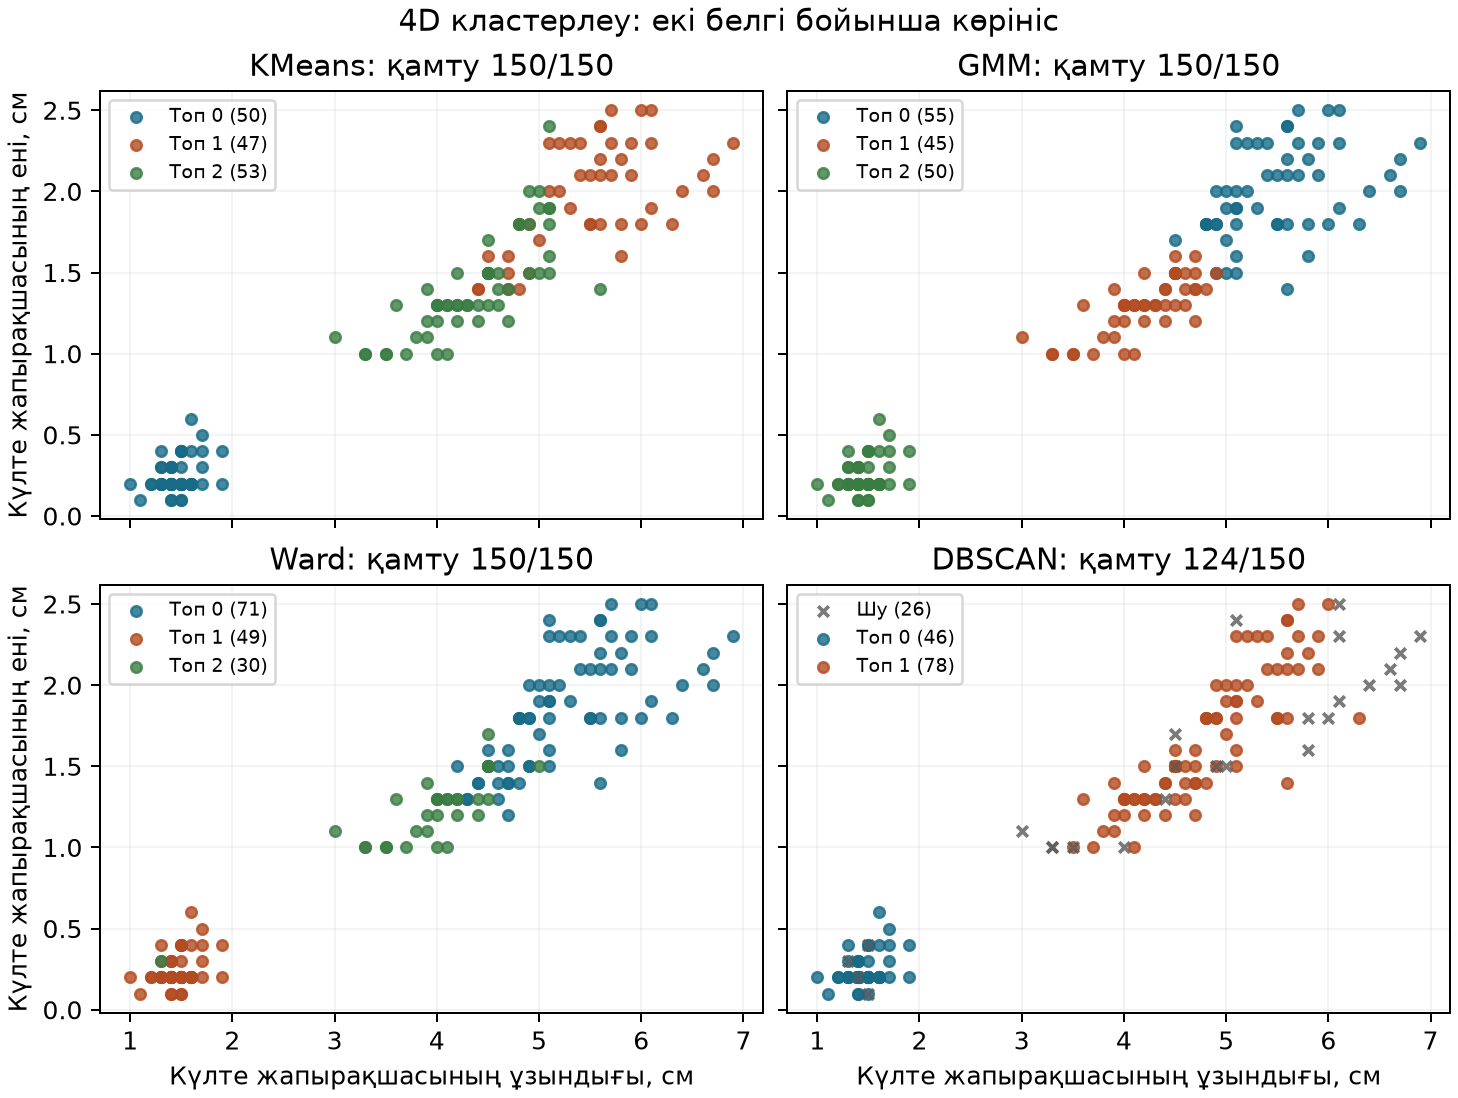

In [5]:
def evaluate_clusters(X, y, state):
    rows = []
    for name, labels in state["labels"].items():
        keep = labels != -1
        n_kept = int(keep.sum())
        values, counts = np.unique(labels[keep], return_counts=True)
        k = len(values)
        silhouette = (float(silhouette_score(state["Z"][keep], labels[keep]))
                      if 2 <= k < n_kept else None)
        rows.append({"model": name, "clusters": k,
                     "cluster_sizes": dict(zip(map(str, values), map(int, counts))),
                     "covered": n_kept, "coverage": n_kept / len(X),
                     "noise": len(X) - n_kept, "silhouette": silhouette,
                     "silhouette_n": n_kept if silhouette is not None else None,
                     "ARI_all": float(adjusted_rand_score(y, labels))})
    display_cols = ["model", "clusters", "covered", "noise", "silhouette",
                    "silhouette_n", "ARI_all"]
    print(pd.DataFrame(rows)[display_cols].to_string(index=False))
    gmm = state["models"]["GMM"]
    print("GMM: жинақталды =", gmm.converged_, "итерациялар =", gmm.n_iter_)
    fig, axes = plt.subplots(2, 2, figsize=(8.1, 6.1), sharex=True, sharey=True,
                             layout="constrained")
    fig.suptitle("4D кластерлеу: екі белгі бойынша көрініс")
    colors = ["#176B87", "#B34B20", "#3A7D43", "#7A5195"]
    for ax, row in zip(axes.ravel(), rows):
        labels = state["labels"][row["model"]]
        for value in sorted(set(labels)):
            mask = labels == value
            color = "#595959" if value == -1 else colors[value % len(colors)]
            label = "Шу" if value == -1 else f"Топ {value}"
            ax.scatter(X.iloc[mask, 2], X.iloc[mask, 3], s=18,
                       marker="x" if value == -1 else "o", color=color, alpha=.8,
                       label=f"{label} ({mask.sum()})", zorder=3 if value == -1 else 2)
        ax.set_title(f"{row['model']}: қамту {row['covered']}/150")
        ax.legend(loc="upper left", fontsize=7.5)
        ax.grid(alpha=.15)
    for ax in axes[1]:
        ax.set_xlabel("Күлте жапырақшасының ұзындығы, см")
    for ax in axes[:, 0]:
        ax.set_ylabel("Күлте жапырақшасының ені, см")
    fig.savefig(FIGURES / "ch08_06_clusters.png", dpi=180)
    plt.close(fig)
    return {"rows": rows, "fit_rows": len(X), "fit_dimensions": X.shape[1],
            "ARI_rows": len(X), "ARI_noise_group": -1,
            "scaler_fit_rows": int(state["scaler"].n_samples_seen_),
            "GMM_converged": bool(gmm.converged_), "GMM_iterations": int(gmm.n_iter_),
            "assignments": {name: labels.tolist() for name, labels in state["labels"].items()}}



y = iris.target
cluster_result = evaluate_clusters(X, y, cluster_state)
display(Image(filename=str(FIGURES / "ch08_06_clusters.png")))


DBSCAN 124 жолды қамтып, 26 жолды шуға қалдырады және 2 топ береді. Оның шамамен .641895 силуэті 124 жолда есептелген. Қалған силуэттер 150 жолды пайдаланады. GMM шамамен .374165 силуэт кезінде шамамен .903874 ARI береді. Екі сан бөлудің әртүрлі қасиеттерін сипаттайды.

**Жауабыңыз.** DBSCAN үшін қамту неге маңызды екенін түсіндіріңіз. Екі метриканың популяцияларын атап, ARI-дегі −1 мағынасын сипаттаңыз. Суреттен координаталары сәйкес келетін мысалды тауып, fit нені ескергенін түсіндіріңіз.

_Өз қорытындыңызды жазыңыз._

### 8–9-қадамдар. PCA проекциясы және test қателері

Сұр нүктелер train-ді, түрлі түсті нүктелер fit-тен кейінгі test түрлерін көрсетеді. Түсіндірілген дисперсия train-ге қатысты. Реконструкция қатесі test-ке қатысты және стандарттық бірліктер квадраттарымен өрнектелген. Train дисперсиясының жиынтық үлесі шамамен .956972. PCA2 орташа MSE қатесі шамамен .037846, ал базалық қате шамамен 1.050322.

Train түсіндірілген дисперсиясы: [2.960597615510984, 0.8994575770117128]
Train түсіндірілген дисперсиясының үлесі: [0.7339814921787654, 0.22299052430082067]
Test-тегі әр стандартталған белгінің MSE қатесі:
           feature     PCA2  TrainMean
sepal length (cm) 0.076728   1.090007
 sepal width (cm) 0.008698   1.267907
petal length (cm) 0.015842   0.936762
 petal width (cm) 0.050117   0.906613
Test орташа MSE қатесі: PCA2 / Train орташа мәні: 0.03784615040746825 1.0503222394262033


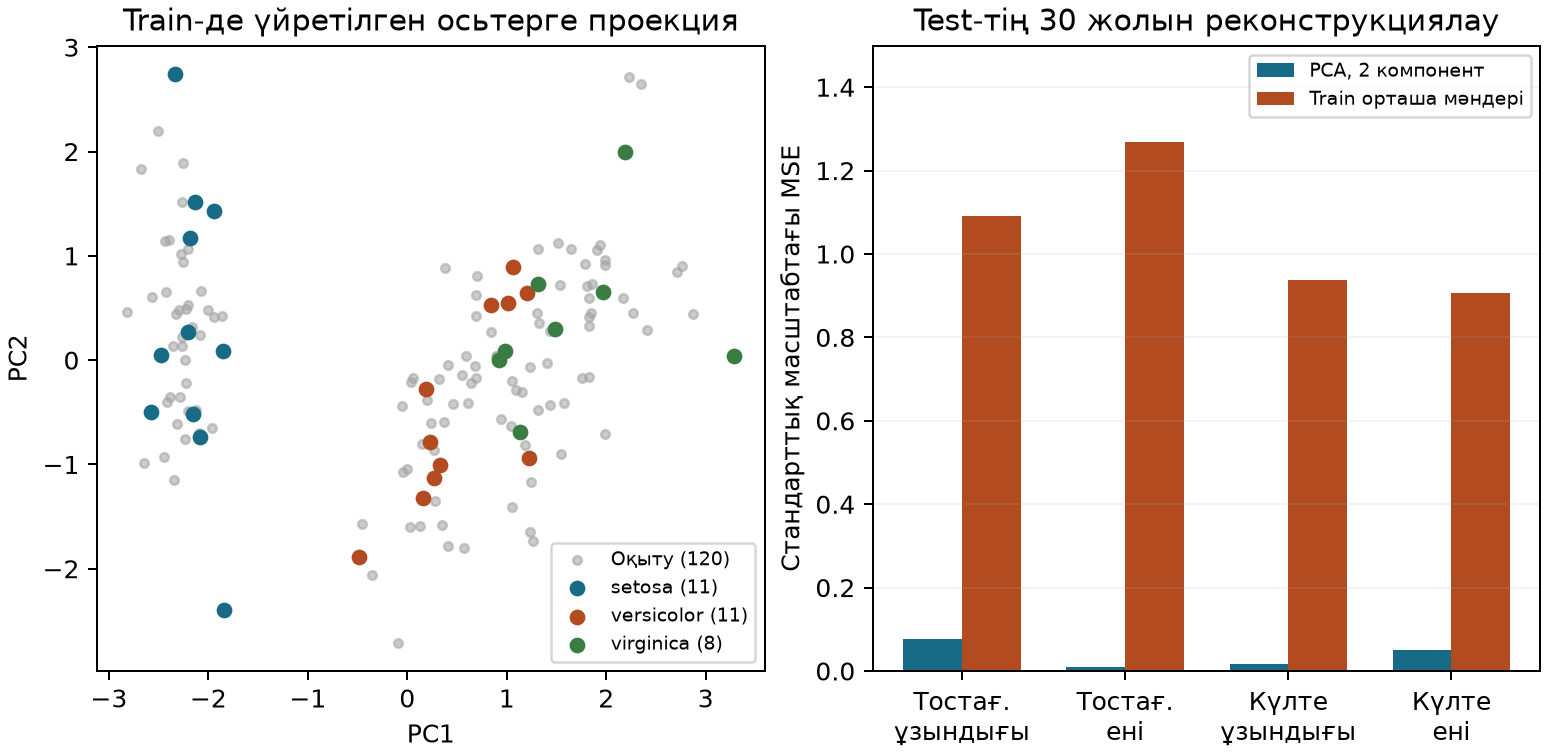

In [6]:
def evaluate_pca(X, y, names, state):
    train, test, pca = state["train"], state["test"], state["pca"]
    metrics = {"feature_names": list(X.columns),
               "MSE_PCA2_by_feature": state["mse"].tolist(),
               "MSE_mean_baseline_by_feature": state["baseline_mse"].tolist(),
               "MSE_PCA2_mean": float(state["mse"].mean()),
               "MSE_mean_baseline_mean": float(state["baseline_mse"].mean()),
               "explained_variance_train": pca.explained_variance_.tolist(),
               "explained_variance_ratio_train": pca.explained_variance_ratio_.tolist(),
               "explained_variance_ratio_sum_train": float(pca.explained_variance_ratio_.sum()),
               "train_indices": train.tolist(), "test_indices": test.tolist(),
               "split_stratified": False, "split_seed": 2026,
               "scaler_fit_rows": int(state["scaler"].n_samples_seen_),
               "PCA_fit_rows": int(pca.n_samples_), "q": pca.n_components_,
               "test_used_to_choose_q": False,
               "test_species_counts_posthoc": np.bincount(y.iloc[test], minlength=3).tolist()}
    print("Train түсіндірілген дисперсиясы:", metrics["explained_variance_train"])
    print("Train түсіндірілген дисперсиясының үлесі:", metrics["explained_variance_ratio_train"])
    print("Test-тегі әр стандартталған белгінің MSE қатесі:\n", pd.DataFrame({
        "feature": X.columns, "PCA2": state["mse"], "TrainMean": state["baseline_mse"]
    }).to_string(index=False))
    print("Test орташа MSE қатесі: PCA2 / Train орташа мәні:", metrics["MSE_PCA2_mean"],
          metrics["MSE_mean_baseline_mean"])
    fig, axes = plt.subplots(1, 2, figsize=(8.6, 4.2), layout="constrained")
    projection = pca.transform(state["Z_train"])
    axes[0].scatter(projection[:, 0], projection[:, 1], s=12, color="#A3A3A3",
                    alpha=.55, label="Оқыту (120)")
    for species, color in enumerate(["#176B87", "#B34B20", "#3A7D43"]):
        mask = y.iloc[test].to_numpy() == species
        projected = state["coordinates"][mask]
        axes[0].scatter(projected[:, 0], projected[:, 1], s=28, color=color,
                        label=f"{names[species]} ({mask.sum()})")
    axes[0].set(xlabel="PC1", ylabel="PC2", title="Train-де үйретілген осьтерге проекция")
    axes[0].legend(fontsize=7.5, loc="best")
    positions = np.arange(X.shape[1])
    axes[1].bar(positions - .18, state["mse"], width=.36,
                label="PCA, 2 компонент", color="#176B87")
    axes[1].bar(positions + .18, state["baseline_mse"], width=.36,
                label="Train орташа мәндері", color="#B34B20")
    axes[1].set(xticks=positions, xticklabels=["Тостағ.\nұзындығы", "Тостағ.\nені",
                                             "Күлте\nұзындығы", "Күлте\nені"],
                ylabel="Стандарттық масштабтағы MSE", title="Test-тің 30 жолын реконструкциялау")
    axes[1].set_ylim(0, 1.5)
    axes[1].legend(fontsize=7.5, loc="upper right")
    axes[1].grid(axis="y", alpha=.15)
    fig.savefig(FIGURES / "ch08_07_pca.png", dpi=180)
    plt.close(fig)
    return metrics



pca_result = evaluate_pca(X, y, iris.target_names, pca_state)
display(Image(filename=str(FIGURES / "ch08_07_pca.png")))


**Жауабыңыз.** Train түсіндірілген дисперсиясының үлесі мен test қатесі неге әртүрлі шамаларды сипаттайды? Проекция бойынша қалпына келтіру базалық орталықпен салыстырғанда жиынтық қате квадратын қалай азайтатынын түсіндіріңіз. Күлте жапырақшасы ұзындығының MSE қатесін см²-ге қалай айналдыруға болады?

_Есептеу мен түсіндірмені жазыңыз._

### 10-қадам. Нәтижелер мен атрибуцияны экспорттау

Төрт бастапқы өлшем, row_id, target, species және pca_split сақталады. Қызметтік өрістер нәтиженің шығу тегін тексеруге қолданылады. Жеке JSON-да сандық метрикалар мен әр объектінің тағайындаулары бар.

In [7]:
def save_artifacts(iris, cluster_result, pca_result, result_path):
    split = np.full(len(iris.data), "test", dtype=object)
    split[pca_result["train_indices"]] = "train"
    iris.data.assign(row_id=np.arange(len(iris.data)), target=iris.target,
                     species=iris.target_names[iris.target.to_numpy()], pca_split=split).to_csv(
        DATASETS / "iris_unsupervised.csv", index=False)
    attribution = DATASETS / "Iris_Attribution.txt"
    if not attribution.exists():
        attribution.write_text(ATTRIBUTION, encoding="utf-8")
    result = {"data": "real corrected sklearn Iris, derived from UCI", "shape": [150, 4],
              "license": "CC BY 4.0", "DOI": "10.24432/C56C76",
              "cluster": cluster_result, "PCA": pca_result}
    result_path.write_text(json.dumps(result, ensure_ascii=False, indent=2), encoding="utf-8")
    return result



result = save_artifacts(iris, cluster_result, pca_result, ROOT / "lab08_results.json")
print("CSV, атрибуция және нәтижелер сақталған орын:", ROOT)


CSV, атрибуция және нәтижелер сақталған орын: lab08_artifacts


### Геометрия мен шекараларды өзіндік тексеру

Тексеру оқыту көлемдерін, метрикалар популяцияларын, бөлу мен реконструкцияны салыстырады. Сандық тұжырымдар осы бекітілген тәжірибеге қатысты.

In [8]:
assert X.shape == (150, 4)
assert cluster_result["scaler_fit_rows"] == 150
assert cluster_result["GMM_converged"]
for row in cluster_result["rows"]:
    labels = np.array(cluster_result["assignments"][row["model"]])
    assert len(labels) == 150 and row["covered"] + row["noise"] == 150
    assert row["covered"] == sum(row["cluster_sizes"].values())
    assert row["silhouette_n"] == row["covered"]
    np.testing.assert_allclose(row["ARI_all"], adjusted_rand_score(y, labels))
train, test = pca_state["train"], pca_state["test"]
assert len(train) == 120 and len(test) == 30
assert not set(train) & set(test)
assert set(train) | set(test) == set(range(150))
assert pca_result["scaler_fit_rows"] == pca_result["PCA_fit_rows"] == 120
np.testing.assert_allclose(pca_state["scaler"].mean_, X.iloc[train].mean())
axes = pca_state["pca"].components_
np.testing.assert_allclose(axes @ axes.T, np.eye(2), atol=1e-12)
test_z = pca_state["Z_test"]
projection_error = ((test_z - pca_state["reconstructed"]) ** 2).sum(axis=1)
baseline_error = ((test_z - pca_state["baseline"]) ** 2).sum(axis=1)
assert np.all(projection_error <= baseline_error + 1e-12)
assert not pca_result["split_stratified"] and not pca_result["test_used_to_choose_q"]
print("Қамту, бөлу, оқыту көлемдері және реконструкция тексерілді.")


Қамту, бөлу, оқыту көлемдері және реконструкция тексерілді.


### Жеке жұмыс, есеп және қорғау

PCA параметрлерін таңдау үшін 120 train ішінде ішкі тексеруді пайдаланыңыз. Негізгі хаттама алдын ала берілген күйде қалады.

1. Екі eps мәнін салыстырып, әр силуэт қамтуын сипаттаңыз.
2. Бір eps кезінде екі min_samples мәнін салыстырыңыз.
3. KMeans-тің екі бастапқы мәнін инерция мен топ көлемдері бойынша салыстырыңыз.
4. GMM-нің full және diag ковариацияларын салыстырыңыз.
5. Train ішкі тексеруінде q=1, 2, 3 салыстырыңыз.
6. Ось пен тиісті координаталар таңбасын өзгертіп, реконструкцияны тексеріңіз.

**Нұсқаңыз.** Шарттарды, критерийді, бақылаулар мен қорытындыны көрсетіңіз.

Есепте атрибуция, баптаулар, 8.3–8.4-кестелер, 8.6–8.7-суреттер және нұсқа нәтижесі болады. Толықтықтың жергілікті шкаласы 100%. Қойылым мен деректер 15%, кластерлеу 20%, метрикалар 20%, PCA 20%, түсіндіру 15%, қайталану мен нұсқа 10% береді. Силлабус 10 ресми балды бөлек көрсетеді.

1. Кластерлеу белгілері матрицасының пішіні қандай?
2. DBSCAN топтарының санын не анықтайды?
3. Шу мен қамту қалай есептеледі?
4. Силуэт қашан анықталған?
5. Әртүрлі қамту силуэттерді салыстыру үшін неге маңызды?
6. −1 ARI-ге қалай қатысады?
7. 8.6-суретте неге екі ось бар?
8. PCA fit кезінде қандай жолдар қолжетімді?
9. Базалық қалпына келтіру қалай құрылады?
10. Train дисперсиясының үлесі тест MSE қатесінен несімен өзгеше?

Бастапқы құжаттама 2026 жылғы 5 қарашада тексерілген. [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html), [силуэт](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html), [ARI](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html).